# Can AI connect to existing business software?

A descriptive analysis of Generativ’s **35-system editorial catalogue**, version 31 October 2026. Review dates are retained per entry. [Search the database](https://www.generativ.co.uk/resources/software-integration-database) · [GitHub](https://github.com/Fantasmagazzle/uk-business-software-integrations).

**No scoped connection-test evidence is recorded in this dataset.** Counts describe documentation coverage, not UK adoption, quality or successful integrations. Unknown is not unavailable. Original curation: CC BY 4.0.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
candidates = [Path('../data/systems.csv'), Path('data/systems.csv')]
candidates += list(Path('/kaggle/input').rglob('systems.csv')) if Path('/kaggle/input').exists() else []
path = next(p for p in candidates if p.exists())
systems = pd.read_csv(path, keep_default_na=False)
assert systems.id.is_unique
print(f'{len(systems)} systems; documentation reviewed {systems.last_checked.min()} to {systems.last_checked.max()}')
systems[['name', 'category', 'minimum_plan', 'webhook_status', 'verification_status']]


35 systems; documentation reviewed 2026-10-16 to 2026-10-31


,name,category,minimum_plan,webhook_status,verification_status
0,Airtable,Productivity,"Free, Team, Business and Enterprise Scale",http,not_tested
1,Asana,Work management,Free and paid accounts,http,not_tested
2,BambooHR,HR,API-enabled account and authorised user; tier ...,http,not_tested
3,BigChange,Field service,REST API licence; confirm contract,not_confirmed,not_tested
4,Calendly,Scheduling,Core API on all plans; webhook subscriptions r...,conditional,not_tested
5,Capsule CRM,CRM,Minimum commercial tier not established,conditional,not_tested
6,ClickUp,Work management,All ClickUp plans,http,not_tested
7,Docusign,Documents and signatures,Production API eligibility and integration app...,conditional,not_tested
8,ERPNext,ERP,An accessible ERPNext/Frappe site with authori...,http,not_tested
9,FreeAgent,Accounting,FreeAgent company account; exact commercial pl...,not_confirmed,not_tested


## 1. Which categories are covered?
This is a coverage check of the selected catalogue. Category counts must not be presented as market share.

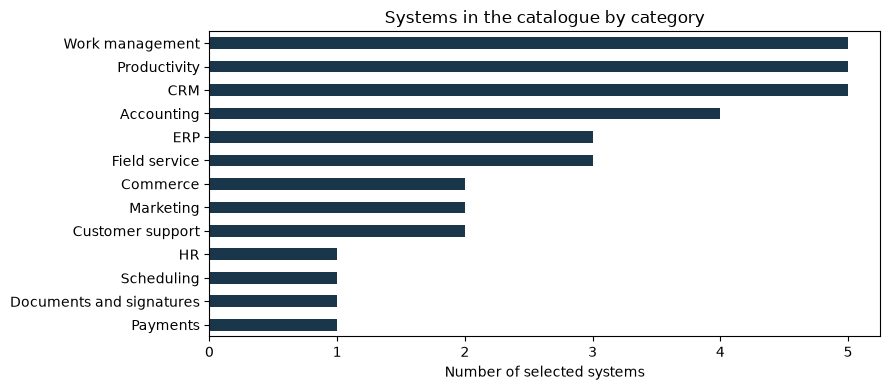

In [2]:
systems.category.value_counts().sort_values().plot.barh(color='#19364b', figsize=(9,4), title='Systems in the catalogue by category')
plt.xlabel('Number of selected systems'); plt.ylabel(''); plt.tight_layout(); plt.show()


## 2. What kind of event delivery is documented?
An HTTP webhook, a plan-restricted webhook and an event stream are different engineering choices. Unconfirmed entries require more research; they are not evidence of no support.

,systems
status,
http,24
conditional,7
not_confirmed,3
event_stream,1


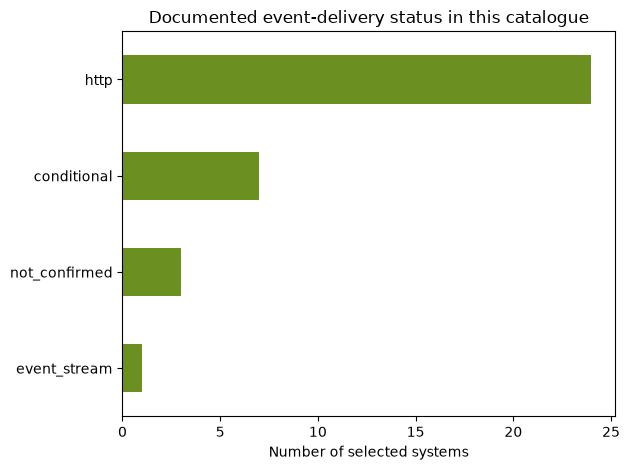

In [3]:
webhooks = systems.webhook_status.value_counts().rename_axis('status').to_frame('systems')
display(webhooks)
webhooks.sort_values('systems').plot.barh(legend=False, color='#6b8f20', title='Documented event-delivery status in this catalogue')
plt.xlabel('Number of selected systems'); plt.ylabel(''); plt.tight_layout(); plt.show()


## 3. Where does scoping need more work?
Use these tables to identify missing plan evidence and connection tests. A documented API does not establish the customer’s licence or permissions.

In [4]:
display(systems.groupby(['plan_status','verification_status']).size().rename('systems').reset_index())
display(systems.loc[systems.plan_status.eq('not_confirmed') | systems.webhook_status.eq('not_confirmed'), ['name','minimum_plan','plan_notes','webhook_status','detail_url']])


,plan_status,verification_status,systems
0,conditional,not_tested,10
1,documented,not_tested,14
2,not_confirmed,not_tested,11


,name,minimum_plan,plan_notes,webhook_status,detail_url
2,BambooHR,API-enabled account and authorised user; tier ...,The reviewed developer documents describe acce...,http,https://www.generativ.co.uk/resources/software...
3,BigChange,REST API licence; confirm contract,The usage policy says REST API access is price...,not_confirmed,https://www.generativ.co.uk/resources/software...
5,Capsule CRM,Minimum commercial tier not established,The reviewed authentication and resource docum...,conditional,https://www.generativ.co.uk/resources/software...
8,ERPNext,An accessible ERPNext/Frappe site with authori...,Frappe documents resource APIs for DocTypes. T...,http,https://www.generativ.co.uk/resources/software...
9,FreeAgent,FreeAgent company account; exact commercial pl...,Official developer guidance requires a FreeAge...,not_confirmed,https://www.generativ.co.uk/resources/software...
13,Jira Cloud,Jira Cloud site; minimum paid edition not esta...,"API access follows scopes, project permissions...",http,https://www.generativ.co.uk/resources/software...
15,Mailchimp,Mailchimp account; operation-specific plan ent...,The developer overview requires an account but...,http,https://www.generativ.co.uk/resources/software...
22,QuickBooks Online,QuickBooks Online company plus Intuit app acce...,The reviewed developer pages establish company...,http,https://www.generativ.co.uk/resources/software...
23,Sage Accounting,Accounting Start for sales invoices; Standard/...,"Sage documents API differences between Start, ...",not_confirmed,https://www.generativ.co.uk/resources/software...
25,ServiceM8,Minimum subscription tier not established,Authentication documentation establishes accou...,http,https://www.generativ.co.uk/resources/software...


## 4. Trace a capability to its source
Join the normalised tables instead of dropping provenance. `true` is vendor-documented support within the notes, not an executed test. `unknown` must remain separate from `false`.

In [5]:
capabilities = pd.read_csv(path.parent / 'capabilities.csv', keep_default_na=False)
sources = pd.read_csv(path.parent / 'sources.csv', keep_default_na=False)
trace = capabilities.assign(source_id=capabilities.source_ids.str.split(' | ', regex=False)).explode('source_id')
trace = trace.merge(sources, left_on=['system_id','source_id'], right_on=['system_id','id'], validate='many_to_one')
display(trace.loc[trace.system_id.eq('xero'), ['entity','read','create','update','notes','title','url','checked_at']])


,entity,read,create,update,notes,title,url,checked_at
59,Invoices,true,true,true,Write permissions and invoice status affect wh...,Accounting API: invoices,https://developer.xero.com/documentation/api/a...,2026-10-16


## 5. API-shape review coverage
The ten additions have selected endpoint shapes. Absence for an original entry means not reviewed, not unsupported. Endpoints describe vendor documentation, not executed tests.

In [6]:
contracts = pd.read_csv(path.parent / "api_contracts.csv", keep_default_na=False)
endpoints = pd.read_csv(path.parent / "endpoints.csv", keep_default_na=False)
print(f"{len(contracts)} of {len(systems)} systems have API-shape reviews; {len(endpoints)} selected endpoint summaries")
display(contracts.merge(systems[["id", "name"]], left_on="system_id", right_on="id")[["name", "version", "request_format", "pagination"]])
display(endpoints.groupby("method").size().rename("selected_endpoints").to_frame())

10 of 35 systems have API-shape reviews; 19 selected endpoint summaries


,name,version,request_format,pagination
0,BambooHR,v1 employee endpoints,GET query parameters for lists; employee updat...,"page[limit] defaults to 250, maximum 2,500; op..."
1,Calendly,v2,GET query parameters with scoped Bearer author...,count defaults to 20 and permits up to 100; pa...
2,Capsule CRM,2,JSON resource dictionaries inside a party wrap...,"page and perPage (default 50, maximum 100); fo..."
3,Docusign,eSignature REST 2.1,JSON envelope definitions with OAuth Bearer au...,The selected operations address one envelope o...
4,ERPNext,Frappe REST v1,JSON document fields for POST and PUT; URL que...,limit_start and limit_page_length; default lis...
5,Microsoft Dynamics 365 Business Central,2.0,JSON OData resource bodies; Bearer authorisati...,Server-driven paging applies. Prefer: odata.ma...
6,Odoo,19 / JSON-2,All model calls use POST with a JSON dictionar...,"For search_read, use the ORM domain, fields, o..."
7,ServiceM8,1.0,GET query parameters; POST field payloads foll...,"cursor=-1; follow x-next-cursor, up to 1,000 r..."
8,Simpro,1.0,JSON bodies for POST/PATCH; page and pageSize ...,page is the page number; pageSize defaults to ...
9,Stripe,v1 Customers; account/request API version also...,Form-encoded parameters for the selected v1 PO...,starting_after or ending_before cursor; limit ...


,selected_endpoints
method,
GET,8
PATCH,2
POST,8
PUT,1


## Interpretation
The useful question is not simply whether a system has an API. Check the required records, plan and app eligibility, permissions, event delivery, quota scope and approval process together. These counts describe the catalogue only. Refer to each official source before implementation and test in an authorised environment.

Please submit corrections and scoped, sanitised test evidence through [GitHub](https://github.com/Fantasmagazzle/uk-business-software-integrations). Cite [Generativ’s database](https://www.generativ.co.uk/resources/software-integration-database), version 2026-10-31, when reusing the curation.